<a href="https://colab.research.google.com/github/Raiqueeee/ML/blob/main/XGBoost.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# XGBoost

## Overview
This notebook trains an XGBoost classifier to predict whether a breast tumour is malignant or benign. It covers loading data, exploring it, scaling the features, splitting the data, training the model, and evaluating it.

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

## Dataset
The Breast Cancer Wisconsin dataset is built into scikit-learn (`sklearn.datasets.load_breast_cancer`). It has 569 samples, 30 features computed from cell nucleus measurements, and a binary target: malignant (0) or benign (1).

In [9]:
cancer = load_breast_cancer(as_frame=True)
X = cancer.data
y = cancer.target
print("Features shape:", X.shape)
print("Target names:", list(cancer.target_names))
df = cancer.frame
print(df.head())

Features shape: (569, 30)
Target names: [np.str_('malignant'), np.str_('benign')]
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fr

In [10]:
print("Class distribution:")
print(pd.Series(y).value_counts())
print("Missing values:", int(df.isnull().sum().sum()))

Class distribution:
target
1    357
0    212
Name: count, dtype: int64
Missing values: 0


## Preprocessing and Train/Test Split
Tree-based models do not strictly need scaling, but scaling is applied here for consistency. The features are standardised with StandardScaler (fitted on the training data only). The data is split 80/20 with stratification.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("Training set:", X_train.shape, "Test set:", X_test.shape)

Training set: (455, 30) Test set: (114, 30)


## Model Training
Train an XGBoost classifier with 100 trees.

In [12]:
model = XGBClassifier(n_estimators=100, random_state=42, eval_metric='logloss')
model.fit(X_train_scaled, y_train)
print("Model trained.")

Model trained.


## Evaluation
Predict on the test set and report accuracy, the classification report, and the confusion matrix.

In [13]:
y_pred = model.predict(X_test_scaled)
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}")
print(classification_report(y_test, y_pred, target_names=cancer.target_names))
print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.9561
              precision    recall  f1-score   support

   malignant       0.97      0.90      0.94        42
      benign       0.95      0.99      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114

Confusion matrix:
[[38  4]
 [ 1 71]]


## Visualization
Confusion matrix heatmap and feature importances from the trained XGBoost model.

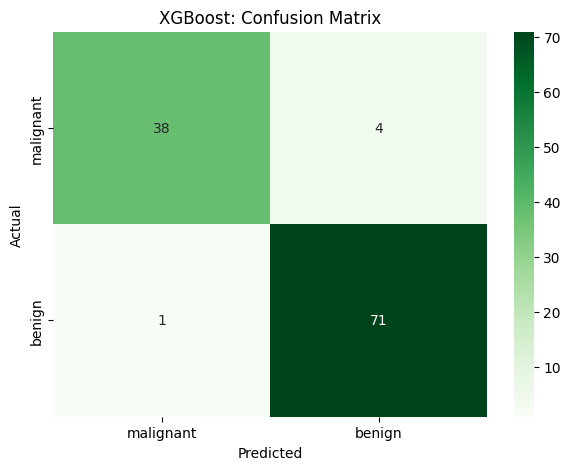

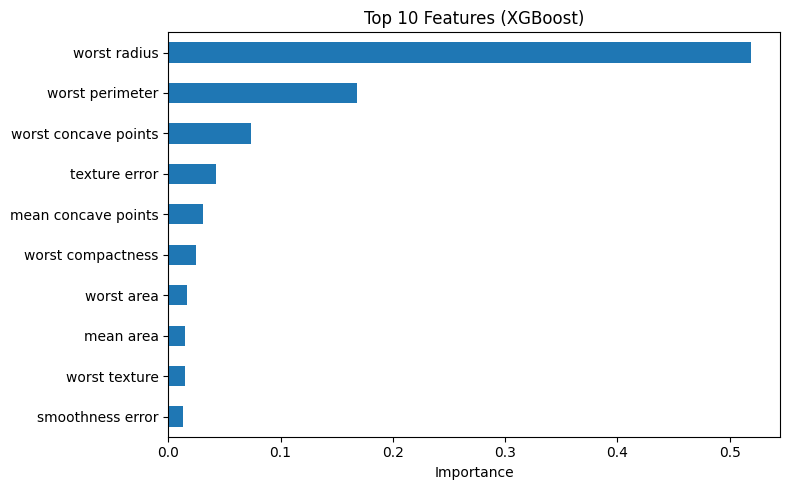

In [14]:
plt.figure(figsize=(7, 5))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Greens',
            xticklabels=cancer.target_names, yticklabels=cancer.target_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('XGBoost: Confusion Matrix')
plt.show()

importances = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
plt.figure(figsize=(8, 5))
importances.sort_values().plot(kind='barh')
plt.xlabel('Importance')
plt.title('Top 10 Features (XGBoost)')
plt.tight_layout()
plt.show()

## Conclusion
XGBoost is a fast, regularised gradient boosting implementation and it performs very well on this dataset. Its built-in feature importances show which measurements matter most.